In [6]:
from pathlib import Path
import os

PROJECT_DIR = Path.cwd()
print("Working directory:", PROJECT_DIR)

for filename in ["Preprocess.py", "Machine learning.py", "EEGNet.py"]:
    print(f"{filename}: {'FOUND' if (PROJECT_DIR / filename).exists() else 'NOT FOUND'}")

print("\nParticipant folders:")
for folder in sorted(PROJECT_DIR.glob("sub-*")):
    if folder.is_dir():
        print(" ", folder.name)

Working directory: /Users/prishasahu/Desktop/EEG-Reproduction
Preprocess.py: FOUND
Machine learning.py: FOUND
EEGNet.py: FOUND

Participant folders:
  sub-01


In [7]:
bdf_files = sorted(PROJECT_DIR.glob("sub-*/ses-*/eeg/*.bdf"))
print("BDF files found:", len(bdf_files))
for path in bdf_files:
    print(path.relative_to(PROJECT_DIR))

BDF files found: 6
sub-01/ses-01/eeg/sub-01_ses-01_task-AVI_eeg.bdf
sub-01/ses-01/eeg/sub-01_ses-01_task-FVI_eeg.bdf
sub-01/ses-01/eeg/sub-01_ses-01_task-OVI_eeg.bdf
sub-01/ses-02/eeg/sub-01_ses-02_task-AVI_eeg.bdf
sub-01/ses-02/eeg/sub-01_ses-02_task-FVI_eeg.bdf
sub-01/ses-02/eeg/sub-01_ses-02_task-OVI_eeg.bdf


In [8]:
%run Preprocess.py


==================== Processing sub-01/ses-01/eeg/sub-01_ses-01_task-AVI_eeg.bdf ====================
===== Start Full EEG Preprocessing Pipeline =====

[Step 1] Read BDF & extract events on original high-sampling raw
Original sampling rate: 1000.0 Hz
Original events count: 120

[Step 2] Resample raw 1000.0Hz → 250Hz, auto sync events

===== Resample Event Time Alignment Check =====
Max time offset between original & resampled events: 0.002000 s
Mean time offset between original & resampled events: 0.000975 s
 Event timing match perfectly after resample, no misalignment!

Sampling rate after resample: 250.0 Hz
Events count after resample: 120

[Step 3] Montage + Average Reference + 1-100Hz Bandpass
Applying standard montage...


/Users/prishasahu/Desktop/EEG-Reproduction/Preprocess.py:61: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = mne.channels.make_standard_montage(montage_name)


Bad channels detected: ['Oz', 'PO4', 'O1', 'PO3']
Applying bandpass filter (1.0-100.0 Hz) before ICA...
Applying average reference...

[Step 4] ICA artifact removal + post-ICA filter
Fitting ICA for artifact removal (picard extended)...
Labeling ICA components...
Excluding 14 non-brain components: [0, 1, 2, 4, 5, 8, 9, 10, 15, 17, 18, 19, 21, 22]
Post-ICA bandpass filter (4.0-80.0 Hz)
Interpolating bad channels: ['Oz', 'PO4', 'O1', 'PO3']

[Step 5] Build MNE standard event array
MNE events array shape: (120, 3)

[Step 6] Epoching based on synced events
Event ID mapping used: {'dog': 1, 'bird': 2, 'fish': 3}

Events actually included in Epochs: {'dog': 1, 'bird': 2, 'fish': 3}
Total valid trials after epoching: 120

Event type dog (ID: 1):
  - Number of segments: 40
  - Data shape: (40, 33, 1001)

Event type bird (ID: 2):
  - Number of segments: 40
  - Data shape: (40, 33, 1001)

Event type fish (ID: 3):
  - Number of segments: 40
  - Data shape: (40, 33, 1001)

===== Preprocessing Pipe

In [9]:
import numpy as np

DATA_DIR = PROJECT_DIR / "ani_s1_signal_sub_newset_del_ch"
print("Output directory exists:", DATA_DIR.exists())

data_files = sorted(DATA_DIR.glob("*_data.npy")) if DATA_DIR.exists() else []
print("Processed recordings:", len(data_files))

for data_file in data_files:
    label_file = data_file.with_name(data_file.name.replace("_data.npy", "_label.npy"))
    if not label_file.exists():
        print("Missing labels for:", data_file.name)
        continue
    X = np.load(data_file)
    y = np.load(label_file)
    counts = dict(zip(*np.unique(y, return_counts=True)))
    print(f"\n{data_file.name}")
    print("  EEG shape:", X.shape)
    print("  Labels shape:", y.shape)
    print("  Class counts:", counts)

Output directory exists: True
Processed recordings: 1

sub-01_ses-01_task-AVI_eeg_data.npy
  EEG shape: (120, 32, 1000)
  Labels shape: (120,)
  Class counts: {np.int64(1): np.int64(40), np.int64(2): np.int64(40), np.int64(3): np.int64(40)}


In [10]:
%run "Machine learning.py"

KNN: 16 parameter combinations

Processing dataset: ani_s1_signal_sub_newset_del_ch

 Found 1 subject files

 Subject [1/1]: sub-01
 Data shape: (120, 32, 1000) | Labels: [1 2 3]

 Evaluating all KNN parameter combinations...

   Evaluation done | Best result:
      Accuracy: 0.4250
      F1: 0.3985
      Precision: 0.4075
      Recall: 0.4250
      Best params: n_neighbors=5, weights=distance, metric=cosine

All subjects processed！


In [11]:
%run EEGNet.py


ani_s1_signal_sub_newset_del_ch: Found  1 subjects

Subject: sub-01_ses-01_task-AVI_eeg_data.npy
Data shape: (120, 32, 1000)

 Sliding window config: window=4.0s, stride=4.0s, 采样率=250Hz

Fold 1/5
Training windows: 96 | Validation window: 24
Epoch 1/1500 | Train Acc: 41.67% | Val Acc: 33.33% | F1: 0.1667
Epoch 31/1500 | Train Acc: 53.12% | Val Acc: 33.33% | F1: 0.1667
Epoch 61/1500 | Train Acc: 58.33% | Val Acc: 29.17% | F1: 0.2451
Epoch 91/1500 | Train Acc: 61.46% | Val Acc: 33.33% | F1: 0.3068
Epoch 121/1500 | Train Acc: 55.21% | Val Acc: 33.33% | F1: 0.3053
Epoch 151/1500 | Train Acc: 56.25% | Val Acc: 37.50% | F1: 0.3370
Epoch 181/1500 | Train Acc: 54.17% | Val Acc: 33.33% | F1: 0.2707
Epoch 211/1500 | Train Acc: 61.46% | Val Acc: 33.33% | F1: 0.2707
Epoch 241/1500 | Train Acc: 69.79% | Val Acc: 33.33% | F1: 0.2707
Epoch 271/1500 | Train Acc: 61.46% | Val Acc: 33.33% | F1: 0.2707
Epoch 301/1500 | Train Acc: 57.29% | Val Acc: 33.33% | F1: 0.2707
Epoch 331/1500 | Train Acc: 63.54% | 

In [12]:
import pandas as pd

summary_rows = []
if DATA_DIR.exists():
    for data_file in sorted(DATA_DIR.glob("*_data.npy")):
        label_file = data_file.with_name(data_file.name.replace("_data.npy", "_label.npy"))
        if not label_file.exists():
            continue
        X = np.load(data_file, mmap_mode="r")
        y = np.load(label_file)
        counts = dict(zip(*np.unique(y, return_counts=True)))
        summary_rows.append({
            "recording": data_file.name,
            "trials": X.shape[0],
            "channels": X.shape[1],
            "samples_per_trial": X.shape[2],
            "class_counts": str(counts),
        })

pd.DataFrame(summary_rows)

,recording,trials,channels,samples_per_trial,class_counts
0,sub-01_ses-01_task-AVI_eeg_data.npy,120,32,1000,"{np.int64(1): np.int64(40), np.int64(2): np.in..."


Total trials: 120

Trials per class:
Dog: 40 trials
Bird: 40 trials
Fish: 40 trials

Balanced-class chance baseline: 33.33%


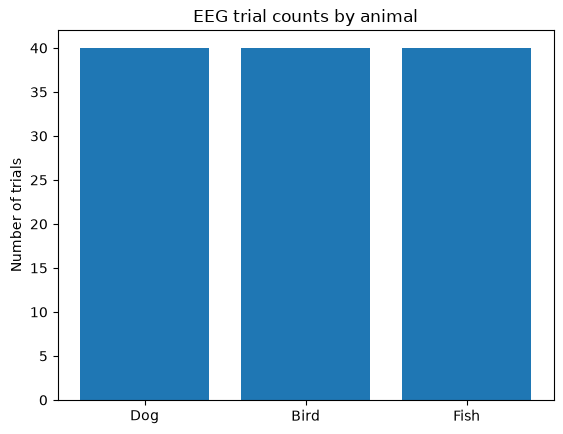

In [13]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

DATA_DIR = Path("ani_s1_signal_sub_newset_del_ch")

label_file = DATA_DIR / "sub-01_ses-01_task-AVI_eeg_label.npy"
y = np.load(label_file)

classes, counts = np.unique(y, return_counts=True)

print("Total trials:", len(y))
print("\nTrials per class:")

animal_names = {1: "Dog", 2: "Bird", 3: "Fish"}

for label, count in zip(classes, counts):
    print(f"{animal_names.get(int(label), str(label))}: {count} trials")

print(f"\nBalanced-class chance baseline: {100 / len(classes):.2f}%")

plt.bar(
    [animal_names.get(int(label), str(label)) for label in classes],
    counts
)
plt.ylabel("Number of trials")
plt.title("EEG trial counts by animal")
plt.show()


ani_s1_signal_sub_newset_del_ch: Found  1 subjects

Subject: sub-01_ses-01_task-AVI_eeg_data.npy
Data shape: (120, 32, 1000)

 Sliding window config: window=4.0s, stride=4.0s, 采样率=250Hz

Fold 1/5
Training windows: 96 | Validation window: 24
Epoch 1/1500 | Train Acc: 41.67% | Val Acc: 33.33% | F1: 0.1667
Epoch 31/1500 | Train Acc: 53.12% | Val Acc: 33.33% | F1: 0.1667
Epoch 61/1500 | Train Acc: 58.33% | Val Acc: 29.17% | F1: 0.2451
Epoch 91/1500 | Train Acc: 61.46% | Val Acc: 33.33% | F1: 0.3068
Epoch 121/1500 | Train Acc: 55.21% | Val Acc: 33.33% | F1: 0.3053
Epoch 151/1500 | Train Acc: 56.25% | Val Acc: 37.50% | F1: 0.3370
Epoch 181/1500 | Train Acc: 54.17% | Val Acc: 33.33% | F1: 0.2707
Epoch 211/1500 | Train Acc: 61.46% | Val Acc: 33.33% | F1: 0.2707
Epoch 241/1500 | Train Acc: 69.79% | Val Acc: 33.33% | F1: 0.2707
Epoch 271/1500 | Train Acc: 61.46% | Val Acc: 33.33% | F1: 0.2707
Epoch 301/1500 | Train Acc: 57.29% | Val Acc: 33.33% | F1: 0.2707
Epoch 331/1500 | Train Acc: 63.54% | 

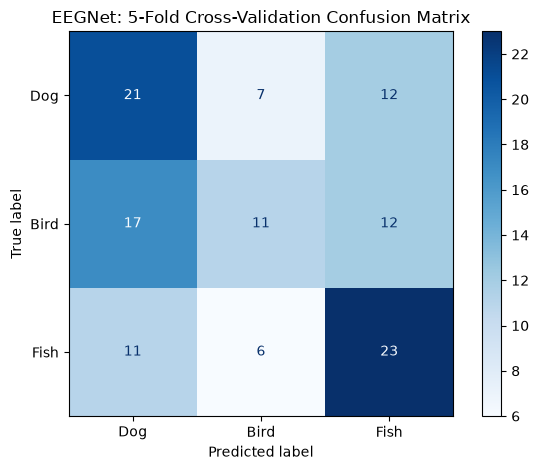


 Program finished


In [15]:
%run EEGNet.py